# DenseNet-121 — Hamiltonian Parameter Regression

**DenseNet-121** backbone trained from scratch for regressing the eight Hamiltonian parameters
from $s_z$ magnetization images (images resized to $224\times224\times3$).


In [1]:
!pip install tensorflow --quiet
!pip install scikit-learn --quiet
!pip install pandas --quiet
!pip install matplotlib --quiet
print("✅ Librerías instaladas. Reinicia el kernel si vienes de una sesión con PyTorch/keras_hub cargado.")

✅ Librerías instaladas. Reinicia el kernel si vienes de una sesión con PyTorch/keras_hub cargado.


In [2]:
import os
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TF: {tf.__version__}")
print(f"GPUs: {tf.config.list_physical_devices('GPU')}")

I0000 00:00:1782835399.019425     369 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1782835399.091795     369 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1782835400.758954     369 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TF: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
DATASET_PATH = "/workspace/Preprocess/latent_space_outputs/dataset_final_estructuras.npz"

data = np.load(DATASET_PATH, allow_pickle=True)
print("Keys:", data.files)

X = np.copy(data['img'])
y = np.copy(data['params'])
label_names = np.copy(data['label_names'])

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"X rango: [{X.min():.3f}, {X.max():.3f}]")
print(f"y rango: [{y.min():.3f}, {y.max():.3f}]")

print("\nDistribución por estructura:")
unique, counts_lbl = np.unique(label_names, return_counts=True)
for u, c in zip(unique, counts_lbl):
    print(f"  {u:15s}: {c:>8,}  ({100*c/len(label_names):.1f}%)")

Keys: ['img', 'params', 'cluster_id', 'label_names']

X shape: (166141, 39, 39, 1)
y shape: (166141, 8)
X rango: [-1.000, 1.000]
y rango: [-0.331, 20.000]

Distribución por estructura:
  Bimerones      :    6,395  (3.8%)
  Ising          :    1,487  (0.9%)
  Others         :   25,310  (15.2%)
  Skyrmiones     :   12,841  (7.7%)
  helical        :  120,108  (72.3%)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1765, random_state=SEED
)

print(f"Train: {X_train.shape[0]:>8,}  ({100*X_train.shape[0]/len(X):.1f}%)")
print(f"Val:   {X_val.shape[0]:>8,}  ({100*X_val.shape[0]/len(X):.1f}%)")
print(f"Test:  {X_test.shape[0]:>8,}  ({100*X_test.shape[0]/len(X):.1f}%)")

Train:  116,293  (70.0%)
Val:     24,926  (15.0%)
Test:    24,922  (15.0%)


In [5]:
scaler = MinMaxScaler()
y_train_scaled = scaler.fit_transform(y_train)
y_val_scaled   = scaler.transform(y_val)
y_test_scaled  = scaler.transform(y_test)

print("Scaler ajustado sobre y_train")
print(f"  rango original: [{y_train.min():.4f}, {y_train.max():.4f}]")
print(f"  rango scaled:   [{y_train_scaled.min():.4f}, {y_train_scaled.max():.4f}]")

Scaler ajustado sobre y_train
  rango original: [-0.3310, 20.0000]
  rango scaled:   [0.0000, 1.0000]


In [6]:
def preprocess_batch(x):
    x = tf.image.resize(x, (224, 224))
    x = tf.image.grayscale_to_rgb(x)
    return x

BATCH_SIZE = 512

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train_scaled))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .map(lambda x, y: (preprocess_batch(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)
val_dataset = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val_scaled))
    .batch(BATCH_SIZE)
    .map(lambda x, y: (preprocess_batch(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)
test_dataset = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test_scaled))
    .batch(BATCH_SIZE)
    .map(lambda x, y: (preprocess_batch(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

print(f"Train batches: {len(train_dataset)}")
print(f"Val batches:   {len(val_dataset)}")
print(f"Test batches:  {len(test_dataset)}")

I0000 00:00:1782835445.002224     369 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 140841 MB memory:  -> device: 0, name: NVIDIA H200, pci bus id: 0000:3a:00.0, compute capability: 9.0a


Train batches: 228
Val batches:   49
Test batches:  49


In [7]:
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import BatchNormalization, Dropout

input_layer = Input(shape=(224, 224, 3))

base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_tensor=input_layer
)

x = GlobalAveragePooling2D()(base_model.output)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
x = Dense(256, activation='relu',
          kernel_regularizer=regularizers.l2(1e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
outputs = Dense(8, activation='linear')(x)

model = Model(inputs=input_layer, outputs=outputs)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='mse',
    metrics=['mae']
)

model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,307,080 (27.87 MB)

 Trainable params: 7,220,872 (27.55 MB)

 Non-trainable params: 86,208 (336.75 KB)

In [8]:
EPOCHS = 40

early_stop = EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.3, patience=4, min_lr=1e-6
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/40


I0000 00:00:1782835526.984270    1016 service.cc:153] XLA service 0x7428d004a980 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1782835526.984343    1016 service.cc:161]   StreamExecutor [0]: NVIDIA H200, Compute Capability 9.0a (Driver: 12.8.0; Runtime: 12.8.0; Toolkit: 12.5.0; DNN: 9.10.2)
I0000 00:00:1782835537.610060    1016 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1782835554.092787    1016 cuda_dnn.cc:461] Loaded cuDNN version 91002
I0000 00:00:1782835555.367685    1016 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_81200__.769
I0000 00:00:1782835652.199772    1571 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 16 bytes spill stores, 16 bytes spill loads

I0000 00:00:1782835677.651232    1512 subprocess_compilation.cc:348] ptxas warning : Regi

227/228 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - loss: 1.2491 - mae: 0.8316

I0000 00:00:1782835874.454555    1016 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_81200__.769
I0000 00:00:1782836059.804819    1016 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_scatter_fusion', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'loop_multiply_fusion_61', 1604 bytes spill stores, 1604 bytes spill loads



228/228 ━━━━━━━━━━━━━━━━━━━━ 626s 2s/step - loss: 1.2488 - mae: 0.8315 - val_loss: 0.3819 - val_mae: 0.4704 - learning_rate: 1.0000e-04
Epoch 2/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 91s 398ms/step - loss: 0.7245 - mae: 0.6125 - val_loss: 0.1758 - val_mae: 0.3131 - learning_rate: 1.0000e-04
Epoch 3/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 70s 305ms/step - loss: 0.5392 - mae: 0.5156 - val_loss: 0.0707 - val_mae: 0.1491 - learning_rate: 1.0000e-04
Epoch 4/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 73s 320ms/step - loss: 0.4152 - mae: 0.4417 - val_loss: 0.0564 - val_mae: 0.1126 - learning_rate: 1.0000e-04
Epoch 5/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 88s 386ms/step - loss: 0.3246 - mae: 0.3820 - val_loss: 0.0499 - val_mae: 0.0903 - learning_rate: 1.0000e-04
Epoch 6/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 71s 308ms/step - loss: 0.2543 - mae: 0.3317 - val_loss: 0.0471 - val_mae: 0.0849 - learning_rate: 1.0000e-04
Epoch 7/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 72s 314ms/step - loss: 0.2006 - mae: 0.2876 - val_loss: 0.0444 - val_mae: 0.077

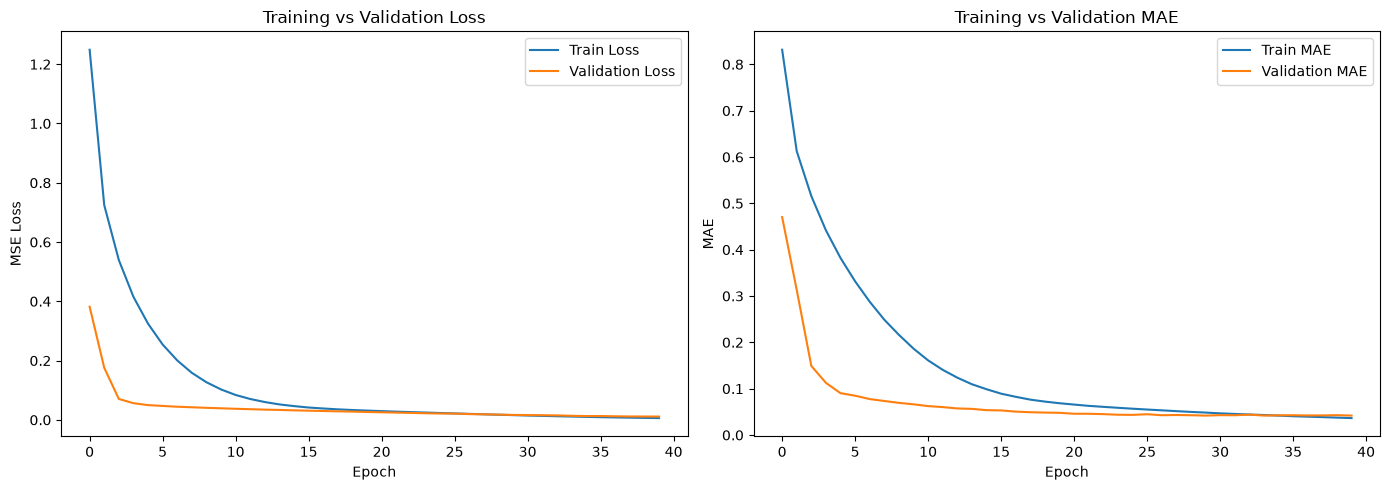

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].legend()

axes[1].plot(history.history['mae'], label='Train MAE')
axes[1].plot(history.history['val_mae'], label='Validation MAE')
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MAE")
axes[1].set_title("Training vs Validation MAE")
axes[1].legend()

plt.tight_layout()
plt.savefig("/workspace/Models/Inverse/Images/densenet_baseline_curves.png", dpi=150, bbox_inches='tight')
plt.show()

In [10]:
y_pred_scaled = model.predict(test_dataset)
y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test_scaled)

param_names = ["T", "Jex2", "Jex3", "Jex4", "Kan1", "KanS", "Hex", "KDM"]

rows = []
for i, name in enumerate(param_names):
    mae  = mean_absolute_error(y_true[:, i], y_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_true[:, i], y_pred[:, i]))
    r2   = r2_score(y_true[:, i], y_pred[:, i])
    rows.append({"Parameter": name, "MAE": round(mae,4), "RMSE": round(rmse,4), "R²": round(r2,4)})

df_metrics = pd.DataFrame(rows).set_index("Parameter").sort_values("R²", ascending=False)
print(df_metrics.to_string())

49/49 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step
              MAE    RMSE      R²
Parameter                        
KDM        0.0320  0.0428  0.9874
Hex        0.0130  0.0207  0.9546
T          0.3905  0.6990  0.9503
Kan1       0.0565  0.1041  0.9038
Jex2       0.0209  0.0514  0.8666
KanS       0.0280  0.0386  0.6166
Jex4       0.0236  0.0595 -0.0602
Jex3       0.0312  0.0806 -0.2142


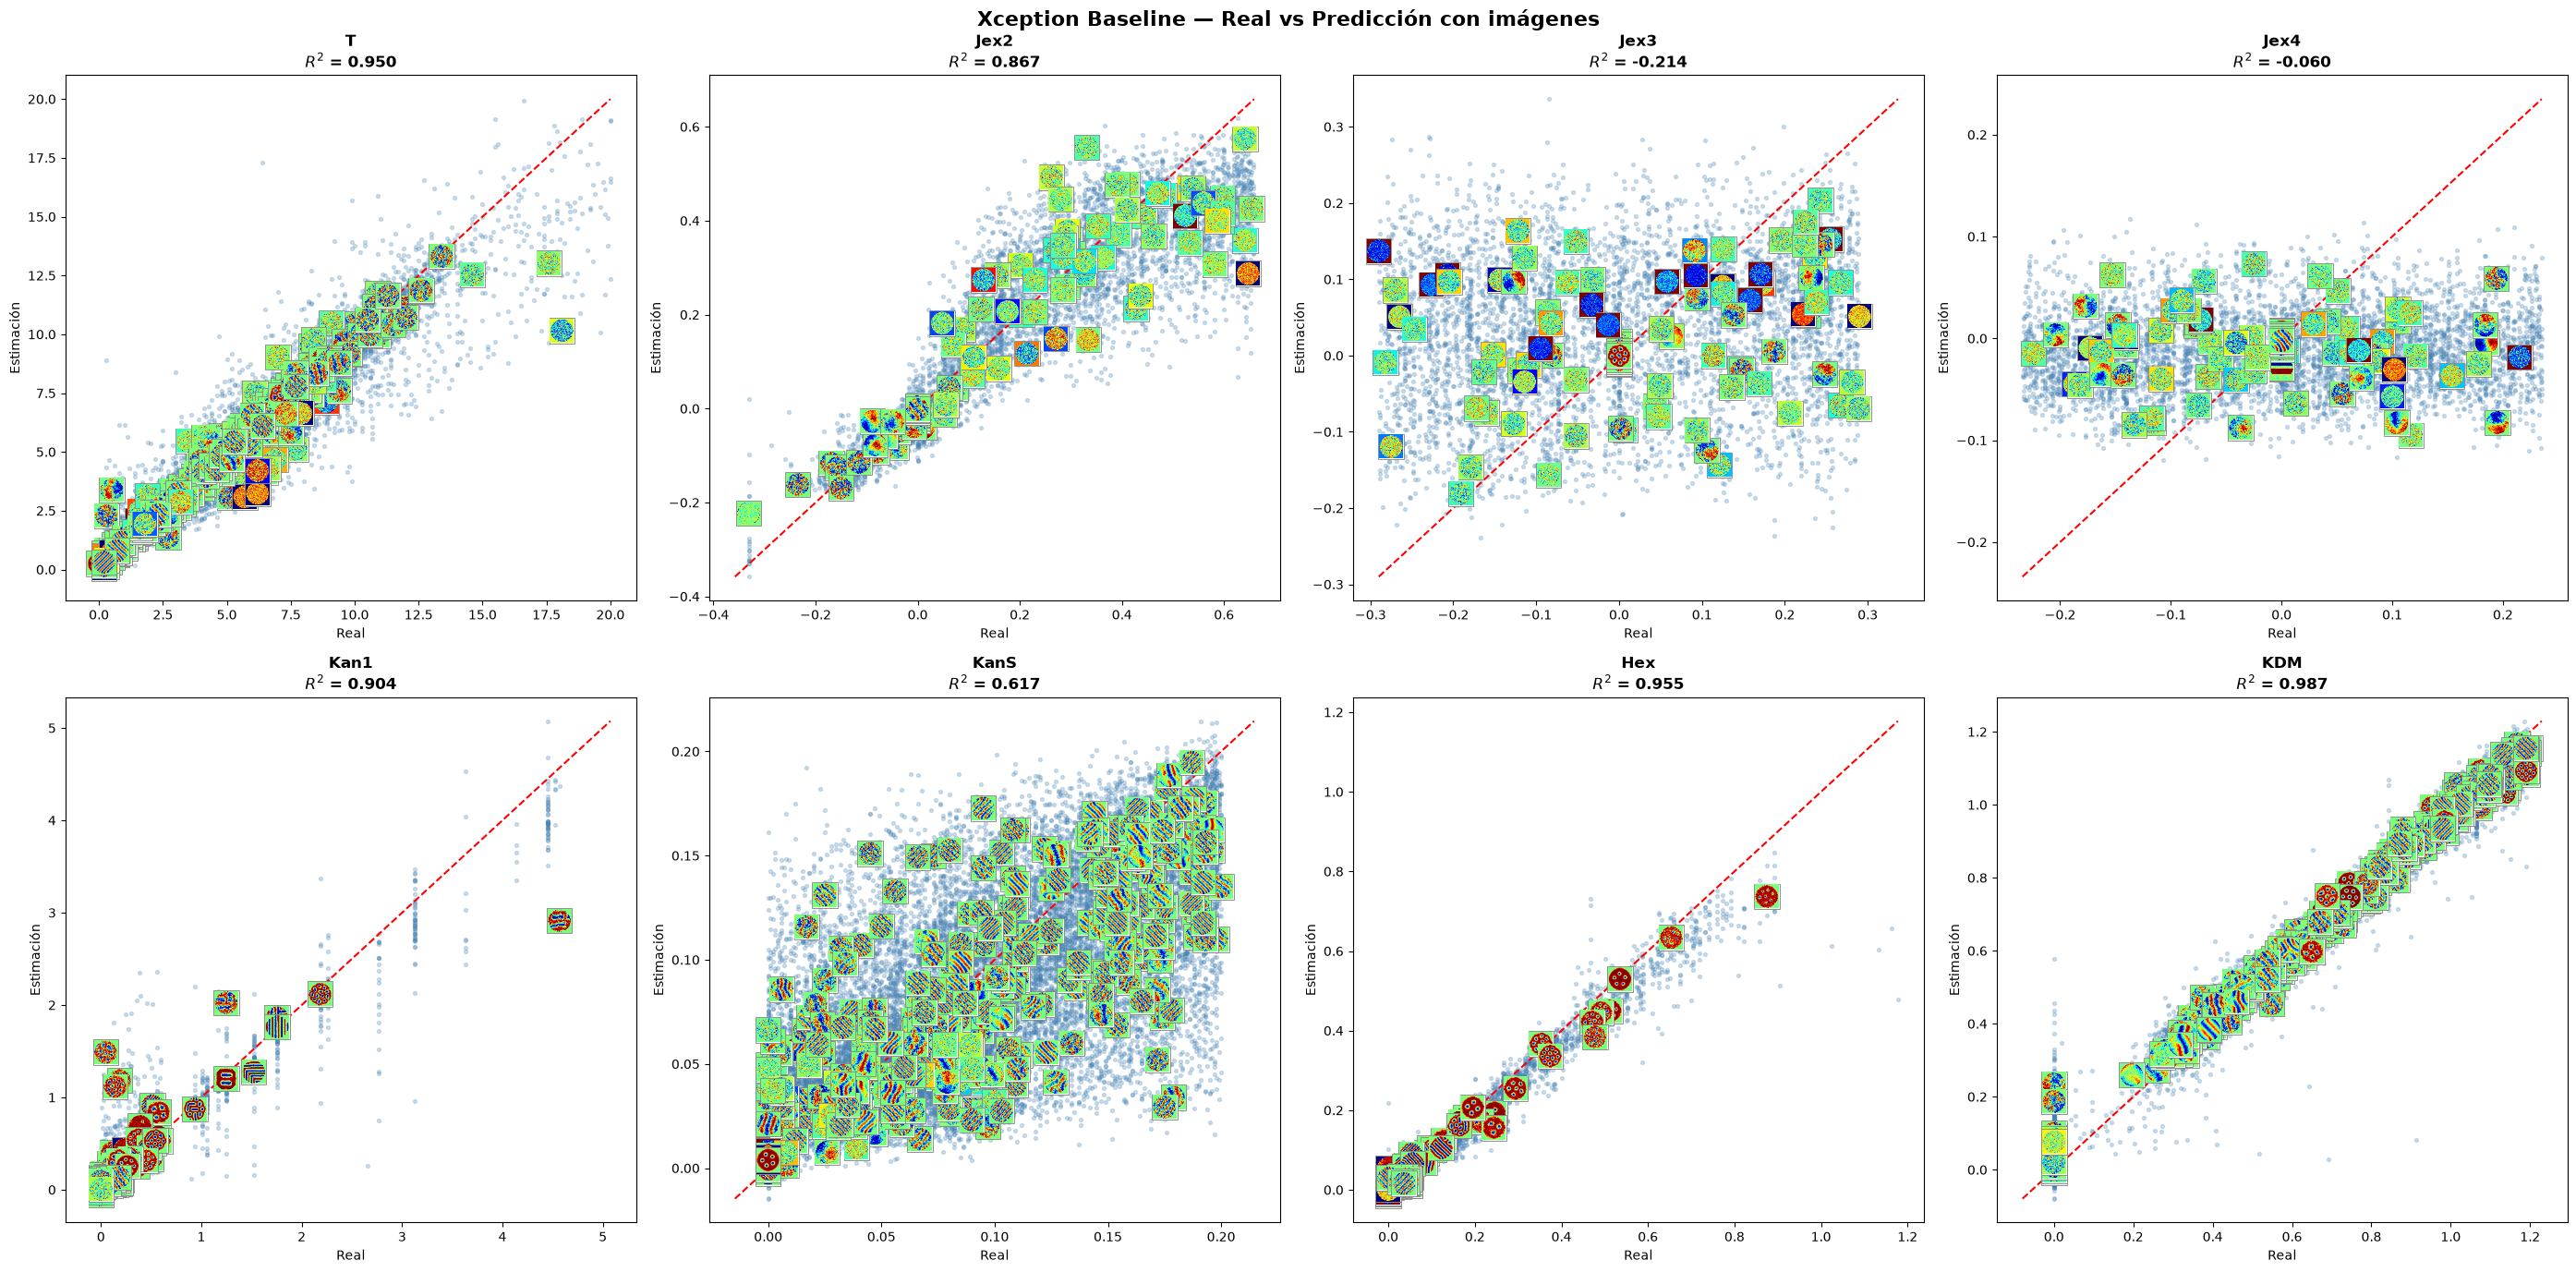

In [11]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

n_outputs = y_true.shape[1]
fig, axes = plt.subplots(2, 4, figsize=(28, 14))
axes = axes.flatten()

N_THUMBS = 400
rng = np.random.RandomState(SEED)

for i in range(n_outputs):
    ax = axes[i]
    name = param_names[i]

    ax.scatter(y_true[:, i], y_pred[:, i], alpha=0.25, s=8, color="steelblue")

    lims = [min(y_true[:,i].min(), y_pred[:,i].min()),
            max(y_true[:,i].max(), y_pred[:,i].max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5)

    # thumbnails — muestra aleatoria simple
    idx_thumbs = rng.choice(len(y_true), size=N_THUMBS, replace=False)

    for idx in idx_thumbs:
        img = X_test[idx, :, :, 0]
        norm_img = (img - img.min()) / (img.max() - img.min() + 1e-8)
        colored = plt.cm.jet(norm_img)[:, :, :3]
        imagebox = OffsetImage(colored, zoom=0.48)
        ab = AnnotationBbox(
            imagebox,
            (y_true[idx, i], y_pred[idx, i]),
            frameon=True,
            bboxprops=dict(edgecolor='gray', linewidth=0.6),
            pad=0.05,
            zorder=3
        )
        ax.add_artist(ab)

    r2 = r2_score(y_true[:, i], y_pred[:, i])
    ax.set_title(f"{name}\n$R^2$ = {r2:.3f}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Real")
    ax.set_ylabel("Estimación")

plt.suptitle("Xception Baseline — Real vs Predicción con imágenes",
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("/workspace/Models/Inverse/Images/densenet_real_vs_pred_thumbs.png",
            dpi=140, bbox_inches="tight")
plt.show()

In [12]:
SAVE_DIR = "/workspace/Models/Inverse/ModelWeights"
os.makedirs(SAVE_DIR, exist_ok=True)

model.save(f"{SAVE_DIR}/modelo_densenet_baseline_estructuras.keras")
print(f"Modelo guardado en {SAVE_DIR}/modelo_densenet_baseline_estructuras.keras")

import pickle
with open(f"{SAVE_DIR}/scaler_densenet_baseline.pkl", 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler guardado.")

Modelo guardado en /workspace/Models/Inverse/ModelWeights/modelo_densenet_baseline_estructuras.keras
Scaler guardado.
